# Prétraitement : UNSW-NB15



## 0. Configuration

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 60)

RANDOM_STATE = 42
N_FOLDS = 5
SKEW_THRESHOLD = 2.0     # au-dessus : log1p
CORR_THRESHOLD = 0.95    # au-dessus : colonne redondante
CATEGORICAL = ["proto", "service", "state"]
TARGETS = ["label", "attack_cat"]

DATA_DIR = Path.cwd() / "data"
if not DATA_DIR.exists():
    DATA_DIR = Path.cwd().parent / "data"
OUT_DIR = DATA_DIR / "processed"
ARTIFACTS_DIR = DATA_DIR.parent / "artifacts"
OUT_DIR.mkdir(exist_ok=True)
ARTIFACTS_DIR.mkdir(exist_ok=True)

## 1. Chargement 

In [2]:
train_raw = pd.read_csv(DATA_DIR / "UNSW_NB15_training-set.csv")
test_raw = pd.read_csv(DATA_DIR / "UNSW_NB15_testing-set.csv")

display(pd.DataFrame({"train": train_raw.shape, "test": test_raw.shape}, index=["lignes", "colonnes"]))


,train,test
lignes,175341,82332
colonnes,45,45


## 2. Cibles et features

In [3]:
y, y_multi = train_raw["label"], train_raw["attack_cat"]
y_test, y_multi_test = test_raw["label"], test_raw["attack_cat"]

X_raw = train_raw.drop(columns=["id"] + TARGETS)
X_test_raw = test_raw.drop(columns=["id"] + TARGETS)

print(f"Train : {len(y)} lignes ; test : {len(y_test)} lignes")
print(f"{X_raw.shape[1]} features brutes, hors identifiant et cibles")

Train : 175341 lignes ; test : 82332 lignes
42 features brutes, hors identifiant et cibles


## 3. Nouvelles variables

In [4]:
def add_features(X):
    X = X.copy()
    X["service"] = X["service"].replace("-", "unknown")
    X["total_bytes"] = X["sbytes"] + X["dbytes"]
    X["total_pkts"] = X["spkts"] + X["dpkts"]
    X["byte_ratio"] = (X["sbytes"] + 1) / (X["dbytes"] + 1)
    X["bytes_per_packet"] = X["total_bytes"] / (X["total_pkts"] + 1)
    X["zero_duration"] = (X["dur"] == 0).astype("int8")
    return X


X_train = add_features(X_raw)
X_test = add_features(X_test_raw)
NUMERIC = [c for c in X_train.columns if c not in CATEGORICAL]
print(f"{len(NUMERIC)} variables numériques, {len(CATEGORICAL)} catégorielles")
display(
    X_train[
        ["sbytes", "dbytes", "spkts", "dpkts", "dur",
         "total_bytes", "total_pkts", "byte_ratio",
         "bytes_per_packet", "zero_duration"]
    ].head()
)

44 variables numériques, 3 catégorielles


,sbytes,dbytes,spkts,dpkts,dur,total_bytes,total_pkts,byte_ratio,bytes_per_packet,zero_duration
0,258,172,6,4,0.121478,430,10,1.497110,39.090909,0
1,734,42014,14,38,0.649902,42748,52,0.017494,806.566038,0
2,364,13186,8,16,1.623129,13550,24,0.027679,542.000000,0
3,628,770,12,12,1.681642,1398,24,0.815824,55.920000,0
4,534,268,10,6,0.449454,802,16,1.988848,47.176471,0


## 4. Doublons, folds et lignes vues dans le train


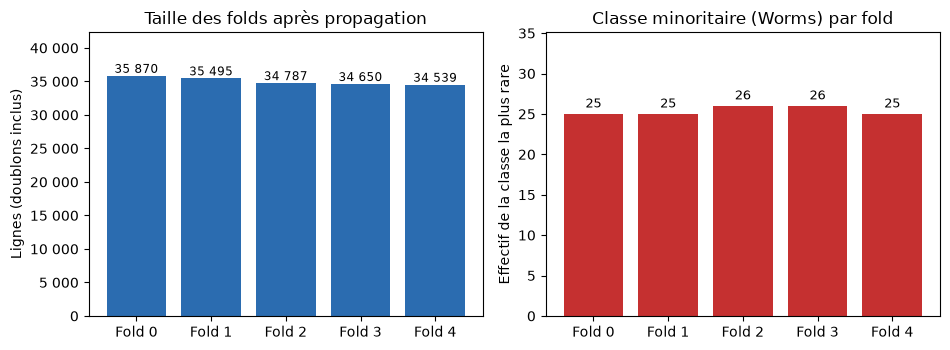

Aucun flux partagé entre entraînement et validation : OK


In [ ]:
hash_cols = [c for c in train_raw.columns if c != "id"]
train_hash = pd.util.hash_pandas_object(train_raw[hash_cols], index=False)
test_hash = pd.util.hash_pandas_object(test_raw[hash_cols], index=False)

is_duplicate = train_hash.duplicated().to_numpy()
in_train = test_hash.isin(set(train_hash)).to_numpy()

unique_idx = np.flatnonzero(~is_duplicate)
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

fold_of_unique = np.full(len(unique_idx), -1)
for fold, (_, val) in enumerate(cv.split(unique_idx, y_multi.iloc[unique_idx])):
    fold_of_unique[val] = fold

hash_to_fold = pd.Series(fold_of_unique, index=train_hash.iloc[unique_idx].to_numpy())
train_fold = train_hash.map(hash_to_fold).astype("int8").to_numpy()

#  taille des folds après propagation et classe minoritaire
rows_per_fold = [int((train_fold == k).sum()) for k in range(N_FOLDS)]
unique_frame = pd.DataFrame({"fold": train_fold[~is_duplicate],
                             "attack_cat": y_multi[~is_duplicate]})
worms_per_fold = [int(((unique_frame["fold"] == k) & (unique_frame["attack_cat"] == "Worms")).sum())
                  for k in range(N_FOLDS)]

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
bars = axes[0].bar([f"Fold {k}" for k in range(N_FOLDS)], rows_per_fold, color="#2b6cb0")
for r, v in zip(bars, rows_per_fold):
    axes[0].text(r.get_x() + r.get_width() / 2, v + 400, f"{v:,}".replace(",", " "),
                 ha="center", fontsize=8.5)
axes[0].set_ylim(0, max(rows_per_fold) * 1.18)
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}".replace(",", " ")))
axes[0].set_ylabel("Lignes (doublons inclus)")
axes[0].set_title("Taille des folds après propagation")
axes[0].grid(axis="x", visible=False)

bars = axes[1].bar([f"Fold {k}" for k in range(N_FOLDS)], worms_per_fold, color="#c53030")
for r, v in zip(bars, worms_per_fold):
    axes[1].text(r.get_x() + r.get_width() / 2, v + 0.8, str(v), ha="center", fontsize=9)
axes[1].set_ylim(0, max(worms_per_fold) * 1.35)
axes[1].set_ylabel("Effectif de la classe la plus rare")
axes[1].set_title("Classe minoritaire (Worms) par fold")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()


# Contrôles : un flux et ses copies restent dans un seul fold
for fold in range(N_FOLDS):
    assert not set(train_hash[train_fold == fold]) & set(train_hash[train_fold != fold]), fold
assert (~is_duplicate).sum() == 107740
assert in_train.sum() == 4247
print("Aucun flux partagé entre entraînement et validation : OK")

## 5. Colonnes numériques : corrélation et log1p

In [ ]:
# Colonnes redondantes : Spearman > seuil, on garde la plus corrélée à label
corr = X_train[NUMERIC].corr(method="spearman").abs().fillna(0)
target_corr = X_train[NUMERIC].corrwith(y, method="spearman").abs().fillna(0)

kept = []
for col in target_corr.sort_values(ascending=False, kind="stable").index:
    if all(corr.loc[col, k] <= CORR_THRESHOLD for k in kept):
        kept.append(col)
redundant = [c for c in NUMERIC if c not in kept]
NUMERIC_LINEAR = kept

# Colonnes à passer en log1p 
skew = X_train[NUMERIC_LINEAR].skew()
skewed = [
    c for c in NUMERIC_LINEAR
    if skew[c] > SKEW_THRESHOLD
    and X_train[c].nunique() >= 3
    and X_train[c].min() >= 0
    and not c.startswith(("ct_", "is_"))
]
not_skewed = [c for c in NUMERIC_LINEAR if c not in skewed]

print(f"{len(redundant)} colonnes redondantes retirées :", redundant)
print(f"{len(skewed)} colonnes en log1p :", skewed)

13 colonnes redondantes retirées : ['spkts', 'dpkts', 'sbytes', 'rate', 'dttl', 'sloss', 'dwin', 'tcprtt', 'ackdat', 'dmean', 'trans_depth', 'ct_ftp_cmd', 'zero_duration']
16 colonnes en log1p : ['dload', 'byte_ratio', 'dbytes', 'total_pkts', 'total_bytes', 'dloss', 'bytes_per_packet', 'sload', 'dinpkt', 'djit', 'sinpkt', 'dur', 'sjit', 'synack', 'smean', 'response_body_len']


## 6. Pipelines

In [ ]:
def make_encoder():
    return OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist", sparse_output=False)

trees_pipeline = ColumnTransformer(
    [("num", "passthrough", NUMERIC), ("cat", make_encoder(), CATEGORICAL)],
    remainder="drop", verbose_feature_names_out=False,
).set_output(transform="pandas")

log_scale = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])
linear_pipeline = ColumnTransformer(
    [("log", log_scale, skewed), ("scale", StandardScaler(), not_skewed), ("cat", make_encoder(), CATEGORICAL)],
    remainder="drop", verbose_feature_names_out=False,
).set_output(transform="pandas")

# Fit sur le train uniquement
X_train_trees = trees_pipeline.fit_transform(X_train)
X_train_linear = linear_pipeline.fit_transform(X_train)
X_test_trees = trees_pipeline.transform(X_test)
X_test_linear = linear_pipeline.transform(X_test)

display(pd.DataFrame(
    {"arbres": [X_train_trees.shape[1], X_test_trees.shape[1]],
     "linéaire": [X_train_linear.shape[1], X_test_linear.shape[1]]},
    index=["colonnes train", "colonnes test"],
))

,arbres,linéaire
colonnes train,62,49
colonnes test,62,49


## 7. Sauvegarde et contrôles

In [8]:
train_meta = pd.DataFrame({
    "label": y, "attack_cat": y_multi, "row_hash": train_hash,
    "fold": train_fold, "is_duplicate": is_duplicate,
})
test_meta = pd.DataFrame({
    "label": y_test, "attack_cat": y_multi_test,
    "row_hash": test_hash, "in_train": in_train,
})

# Aucune métadonnée ne doit se retrouver dans les features
assert not (set(train_meta.columns) & set(X_train_trees.columns))
assert not (set(test_meta.columns) & set(X_test_trees.columns))

tables = {
    "trees_train": (X_train_trees, train_meta), "trees_test": (X_test_trees, test_meta),
    "linear_train": (X_train_linear, train_meta), "linear_test": (X_test_linear, test_meta),
}
for name, (features, meta) in tables.items():
    pd.concat([features, meta], axis=1).to_parquet(OUT_DIR / f"{name}.parquet", index=False)

joblib.dump(trees_pipeline, ARTIFACTS_DIR / "pipeline_trees.joblib")
joblib.dump(linear_pipeline, ARTIFACTS_DIR / "pipeline_linear.joblib")

reloaded = joblib.load(ARTIFACTS_DIR / "pipeline_trees.joblib")
assert reloaded.transform(X_train.head(3)).shape == (3, X_train_trees.shape[1])
print("Fichiers enregistrés dans", OUT_DIR.as_posix(), "et", ARTIFACTS_DIR.as_posix())

Fichiers enregistrés dans C:/Users/PC/campus-network-traffic-classification/data/processed et C:/Users/PC/campus-network-traffic-classification/artifacts
